# YOLO26n fine-tuned Google Colab

Treina a versão fine-tuned no WIDER FACE a partir do mesmo `yolo26n.pt` da comparação local.
O YOLO base e o YOLOv8n-Face são usados como referências na avaliação final.

1. Abrir este notebook no [Google Colab](https://colab.research.google.com/) através de **Ficheiro → Carregar notebook**.
2. Selecionar **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**.
3. No Google Drive, criar `AIA_TP1_colab` dentro de `O meu disco` e carregar `aia_tp1_colab.zip` nessa pasta.
   O ZIP foi preparado em `colab/aia_tp1_colab.zip` no projeto local e contém código e pesos, sem o dataset.
4. Executar as células por ordem e autorizar a montagem do Drive quando solicitada.

O dataset é descarregado automaticamente para o disco temporário do Colab. Os checkpoints são guardados
no Drive **a cada época**. Uma nova sessão exige voltar a preparar o ambiente e os dados, mas permite
retomar este treino através de `last.pt`.

**100 é o limite de épocas.** Com `PATIENCE=15`, o treino pode terminar antes por falta de melhoria.
Para executar exatamente 100 épocas, definir `PATIENCE=0`. Duas épocas ou uma interrupção não representam
um treino completo. O número realmente concluído fica em `results.csv`.

As GPUs e a duração da sessão dependem da disponibilidade do Colab; o plano gratuito pode terminar antes
de concluir o treino. [Limites e utilização do Colab](https://research.google.com/colaboratory/faq.html)

In [ ]:
# Instalar a mesma versão de Ultralytics usada na comparação local.
# Manter o PyTorch/CUDA que já vem instalado no Colab.
import subprocess
import sys
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "ultralytics==8.4.181", "scipy>=1.11",
])

0

In [ ]:
import csv
import hashlib
import json
import shutil
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import urlopen

import torch
import yaml
from IPython.display import display, Image as DisplayImage
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError("Ativar GPU no tipo de ambiente de execução antes de treinar.")
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM total (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))
print("PyTorch:", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
VRAM total (GiB): 14.6
PyTorch: 2.11.0+cu130


## Drive e configuração

Usar um novo `RUN_NAME` para um experimento diferente. Repetir o mesmo nome retoma o treino interrompido
ou apresenta o treino já concluído, sem o reiniciar. Para voltar depois de uma desconexão, executar
novamente desde o início, mantendo `RUN_NAME`, `EPOCHS` e as definições do experimento.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT = Path("/content/drive/MyDrive/AIA_TP1_colab")
PROJECT_ROOT = Path("/content/AIA_TP1")
BUNDLE_ON_DRIVE = DRIVE_PROJECT / "aia_tp1_colab.zip"
RUN_NAME = "yolo26n_wider_100ep_v1"
RUN_DIR = DRIVE_PROJECT / "runs" / RUN_NAME

EPOCHS = 100
PATIENCE = 15                   # 0 desativa a paragem antecipada.
IMG_SIZE = 640
BATCH_SIZE = 8                  # Se faltar memória GPU, reduzir para 4.
WORKERS = 2
AMP = True
SEED = 2
RUN_TRAINING = True
RESUME_INTERRUPTED = True
RESUME_FROM = None              # Opcional: Path para um checkpoint periódico deste experimento.
RUN_OFFICIAL_EVALUATION = True
CACHE_ARCHIVES_ON_DRIVE = False # True conserva também os ZIPs do dataset no Drive.

if not BUNDLE_ON_DRIVE.is_file():
    raise FileNotFoundError(f"Carregar aia_tp1_colab.zip para {DRIVE_PROJECT}")
DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def extract_zip(archive_path, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination):
                raise ValueError(f"Caminho inesperado no ZIP: {member.filename}")
        archive.extractall(destination)

local_bundle = Path("/content/aia_tp1_colab.zip")
shutil.copy2(BUNDLE_ON_DRIVE, local_bundle)
extract_zip(local_bundle, PROJECT_ROOT)
bundle_manifest = json.loads((PROJECT_ROOT / "bundle_manifest.json").read_text())
for name, expected_hash in bundle_manifest["files"].items():
    if sha256_file(PROJECT_ROOT / name) != expected_hash:
        raise ValueError(f"Ficheiro do pacote diferente do esperado: {name}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts.face_comparison import prepare_yolo_split
from scripts.run_wider_comparison import default_model_specs, run_wider_comparison
print("Código e pesos verificados:", PROJECT_ROOT)

Código e pesos verificados: /content/AIA_TP1


## Preparar o WIDER FACE no disco local do Colab

São descarregados cerca de **1,8 GB** de ZIPs, além do espaço necessário para extrair as imagens.
As imagens são lidas de `/content`, evitando milhares de acessos ao Drive durante o treino.
Se já tiver os três ZIPs, pode colocá-los em `AIA_TP1_colab/dataset_archives` para os reutilizar.
Os links são os usados pelo [projeto YOLOv8-Face de Lindevs](https://github.com/lindevs/yolov8-face/blob/master/download.py).

In [ ]:
DATASET_ROOT = PROJECT_ROOT / "dataset"
ARCHIVES_LOCAL = PROJECT_ROOT.parent / "wider_archives"
ARCHIVES_DRIVE = DRIVE_PROJECT / "dataset_archives"
ARCHIVES_LOCAL.mkdir(parents=True, exist_ok=True)
archive_specs = [
    ("WIDER_train.zip", "WIDER_train/images", "https://huggingface.co/datasets/wider_face/resolve/main/data/WIDER_train.zip"),
    ("WIDER_val.zip", "WIDER_val/images", "https://huggingface.co/datasets/wider_face/resolve/main/data/WIDER_val.zip"),
    ("wider_face_split.zip", "wider_face_split/wider_face_train_bbx_gt.txt", "https://huggingface.co/datasets/wider_face/resolve/main/data/wider_face_split.zip"),
]

def download_archive(url, destination):
    partial = destination.with_suffix(destination.suffix + ".part")
    with urlopen(url, timeout=120) as response, partial.open("wb") as output:
        total = int(response.headers.get("Content-Length", 0))
        received = 0
        last_report = 0
        while True:
            block = response.read(8 * 1024 * 1024)
            if not block:
                break
            output.write(block)
            received += len(block)
            if received - last_report >= 128 * 1024 * 1024:
                print(f"  {received / 1024**2:.0f} MiB / {total / 1024**2:.0f} MiB", flush=True)
                last_report = received
        if total and received != total:
            raise IOError(f"Download incompleto: {destination.name}")
    if not zipfile.is_zipfile(partial):
        raise ValueError(f"O download não é um ZIP válido: {destination.name}")
    partial.replace(destination)

for archive_name, expected_path, url in archive_specs:
    extraction_marker = DATASET_ROOT / f".{archive_name}.extracted.json"
    if extraction_marker.is_file() and (DATASET_ROOT / expected_path).exists():
        print("Já extraído por completo:", archive_name)
        continue
    local_archive = ARCHIVES_LOCAL / archive_name
    if not local_archive.is_file():
        if (ARCHIVES_DRIVE / archive_name).is_file():
            print("Copiar do Drive:", archive_name, flush=True)
            copying = local_archive.with_suffix(local_archive.suffix + ".copying")
            shutil.copy2(ARCHIVES_DRIVE / archive_name, copying)
            if not zipfile.is_zipfile(copying):
                raise ValueError(f"ZIP no Drive incompleto ou inválido: {archive_name}")
            copying.replace(local_archive)
        else:
            print("Descarregar:", archive_name, flush=True)
            download_archive(url, local_archive)
            if CACHE_ARCHIVES_ON_DRIVE:
                ARCHIVES_DRIVE.mkdir(parents=True, exist_ok=True)
                drive_copying = ARCHIVES_DRIVE / f"{archive_name}.copying"
                shutil.copy2(local_archive, drive_copying)
                drive_copying.replace(ARCHIVES_DRIVE / archive_name)
    print("Extrair:", archive_name, flush=True)
    extract_zip(local_archive, DATASET_ROOT)
    if not (DATASET_ROOT / expected_path).exists():
        raise FileNotFoundError(DATASET_ROOT / expected_path)
    extraction_marker.write_text(json.dumps({"archive": archive_name, "url": url}))
print("Dataset disponível:", DATASET_ROOT)

Descarregar: WIDER_train.zip
  128 MiB / 1398 MiB
  256 MiB / 1398 MiB
  384 MiB / 1398 MiB
  512 MiB / 1398 MiB
  640 MiB / 1398 MiB
  768 MiB / 1398 MiB
  896 MiB / 1398 MiB
  1024 MiB / 1398 MiB
  1152 MiB / 1398 MiB
  1280 MiB / 1398 MiB
Extrair: WIDER_train.zip
Descarregar: WIDER_val.zip
  128 MiB / 346 MiB
  256 MiB / 346 MiB
Extrair: WIDER_val.zip
Descarregar: wider_face_split.zip
Extrair: wider_face_split.zip
Dataset disponível: /content/AIA_TP1/dataset


In [ ]:
TRAIN_ANNO = DATASET_ROOT / "wider_face_split/wider_face_train_bbx_gt.txt"
VAL_ANNO = DATASET_ROOT / "wider_face_split/wider_face_val_bbx_gt.txt"
label_fingerprint = {
    "train_annotations": sha256_file(TRAIN_ANNO),
    "val_annotations": sha256_file(VAL_ANNO),
    "converter": sha256_file(PROJECT_ROOT / "scripts/face_comparison.py"),
}
prepared_marker = DATASET_ROOT / "labels_prepared.json"
prepared = json.loads(prepared_marker.read_text()) if prepared_marker.is_file() else {}
if prepared.get("fingerprint") != label_fingerprint:
    split_stats = {}
    for split, annotation, expected_images in (("train", TRAIN_ANNO, 12880), ("val", VAL_ANNO, 3226)):
        images = DATASET_ROOT / f"WIDER_{split}/images"
        stats = prepare_yolo_split(images, annotation, images.parent / "labels")
        if stats["images"] != expected_images:
            raise ValueError(f"Número de imagens inesperado em {split}: {stats}")
        split_stats[split] = stats
        print(split, stats, flush=True)
    prepared_marker.write_text(json.dumps({"fingerprint": label_fingerprint, "stats": split_stats}, indent=2))
else:
    print("Labels já preparadas:", prepared["stats"])

DATA_YAML = PROJECT_ROOT / "wider_face_colab.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(DATASET_ROOT), "train": "WIDER_train/images", "val": "WIDER_val/images", "names": {0: "face"},
}, sort_keys=False))
print(DATA_YAML.read_text())

train {'images': 12880, 'faces': 156994, 'dropped_boxes': 0}
val {'images': 3226, 'faces': 39112, 'dropped_boxes': 0}
path: /content/AIA_TP1/dataset
train: WIDER_train/images
val: WIDER_val/images
names:
  0: face



## Treinar ou retomar o experimento de 100 épocas

O novo experimento começa nos pesos COCO originais, preservando a comparação antes/depois.
O checkpoint antigo de duas épocas não é usado para iniciar este experimento.

Para retomar uma sessão interrompida, manter `RESUME_INTERRUPTED=True`. O `last.pt` deste treino restaura
época, otimizador e scheduler. O objetivo de 100 épocas é o do treino original, não 100 épocas adicionais.
Um checkpoint do treino antigo configurado para 50 épocas não se transforma num treino de 100 apenas
por passar `epochs=100` com `resume=True`.

`best.pt` é escolhido automaticamente pela validação. Uma conclusão normal ou paragem antecipada
remove o estado do otimizador dos pesos finais; nesse caso, o notebook passa à avaliação.
Há checkpoints periódicos adicionais a cada cinco épocas. Se `last.pt` ficar danificado numa interrupção,
selecionar um desses ficheiros em `RESUME_FROM`.
[Retoma de treinos no Ultralytics](https://docs.ultralytics.com/modes/train#resuming-interrupted-trainings)

Se um treino já terminou por paragem antecipada, mudar `PATIENCE` não prolonga os pesos finais.
Para um novo experimento de exatamente 100 épocas, escolher outro `RUN_NAME` e `PATIENCE=0`.

In [ ]:
BASE_WEIGHTS = PROJECT_ROOT / "yolo26n.pt"
LAST_WEIGHTS = RUN_DIR / "weights/last.pt"
BEST_WEIGHTS = RUN_DIR / "weights/best.pt"
RUN_DIR.mkdir(parents=True, exist_ok=True)
experiment_file = RUN_DIR / "experiment.json"
experiment = {
    "epochs_limit": EPOCHS, "imgsz": IMG_SIZE, "seed": SEED,
    "base_sha256": sha256_file(BASE_WEIGHTS), "dataset": label_fingerprint,
}
if experiment_file.is_file():
    if json.loads(experiment_file.read_text()) != experiment:
        raise ValueError("RUN_NAME já pertence a outro experimento. Escolher um novo nome.")
else:
    experiment_file.write_text(json.dumps(experiment, indent=2))

training_clock = {}
def epoch_started(trainer):
    training_clock["started"] = time.perf_counter()

def epoch_finished(trainer):
    elapsed = time.perf_counter() - training_clock.get("started", time.perf_counter())
    completed = trainer.epoch + 1
    remaining_hours = max(trainer.epochs - completed, 0) * elapsed / 3600
    print(
        f"[Colab] Época {completed}/{trainer.epochs} | "
        f"mAP50={trainer.metrics.get('metrics/mAP50(B)', 0):.4f} | "
        f"mAP50–95={trainer.metrics.get('metrics/mAP50-95(B)', 0):.4f} | "
        f"estimativa restante sem paragem antecipada: {remaining_hours:.1f} h",
        flush=True,
    )

checkpoint = Path(RESUME_FROM) if RESUME_FROM else LAST_WEIGHTS
if RUN_TRAINING:
    if checkpoint.is_file():
        training_model = YOLO(str(checkpoint))
        ckpt = training_model.ckpt
        if ckpt.get("train_args", {}).get("epochs") != EPOCHS:
            raise ValueError("Este checkpoint não pertence ao treino com o limite de épocas indicado.")
        if ckpt.get("epoch", -1) < 0 or ckpt.get("optimizer") is None or ckpt.get("epoch", -1) + 1 >= EPOCHS:
            print("Checkpoint final disponível; seguir para a avaliação de best.pt.")
        else:
            if not RESUME_INTERRUPTED:
                raise ValueError("Já existe treino interrompido. Ativar RESUME_INTERRUPTED ou mudar RUN_NAME.")
            training_model.add_callback("on_train_epoch_start", epoch_started)
            training_model.add_callback("on_fit_epoch_end", epoch_finished)
            training_model.train(
                resume=True, data=str(DATA_YAML), device=0, workers=WORKERS,
                batch=BATCH_SIZE, patience=PATIENCE, save_period=5, save_dir=str(RUN_DIR),
            )
    else:
        if RESUME_FROM:
            raise FileNotFoundError(checkpoint)
        if BEST_WEIGHTS.exists() or (RUN_DIR / "results.csv").exists():
            raise ValueError("Treino existente sem last.pt. Escolher recuperação em RESUME_FROM ou outro RUN_NAME.")
        training_model = YOLO(str(BASE_WEIGHTS))
        training_model.add_callback("on_train_epoch_start", epoch_started)
        training_model.add_callback("on_fit_epoch_end", epoch_finished)
        training_model.train(
            data=str(DATA_YAML), epochs=EPOCHS, patience=PATIENCE,
            imgsz=IMG_SIZE, batch=BATCH_SIZE, device=0, workers=WORKERS,
            amp=AMP, seed=SEED, deterministic=True, cache=False,
            save=True, save_period=5, save_dir=str(RUN_DIR), exist_ok=True,
            project=str(RUN_DIR.parent), name=RUN_NAME, pretrained=True,
        )
else:
    print("Treino desativado. Usar o checkpoint já existente:", BEST_WEIGHTS)
if "training_model" in globals():
    del training_model
    torch.cuda.empty_cache()
print("Pasta persistente do treino:", RUN_DIR)

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/AIA_TP1/wider_face_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1962, mixup=0.0, mode=train, model=/content/d

Épocas efetivamente concluídas: 100
Melhores pesos: /content/drive/MyDrive/AIA_TP1_colab/runs/yolo26n_wider_100ep_v1/weights/best.pt


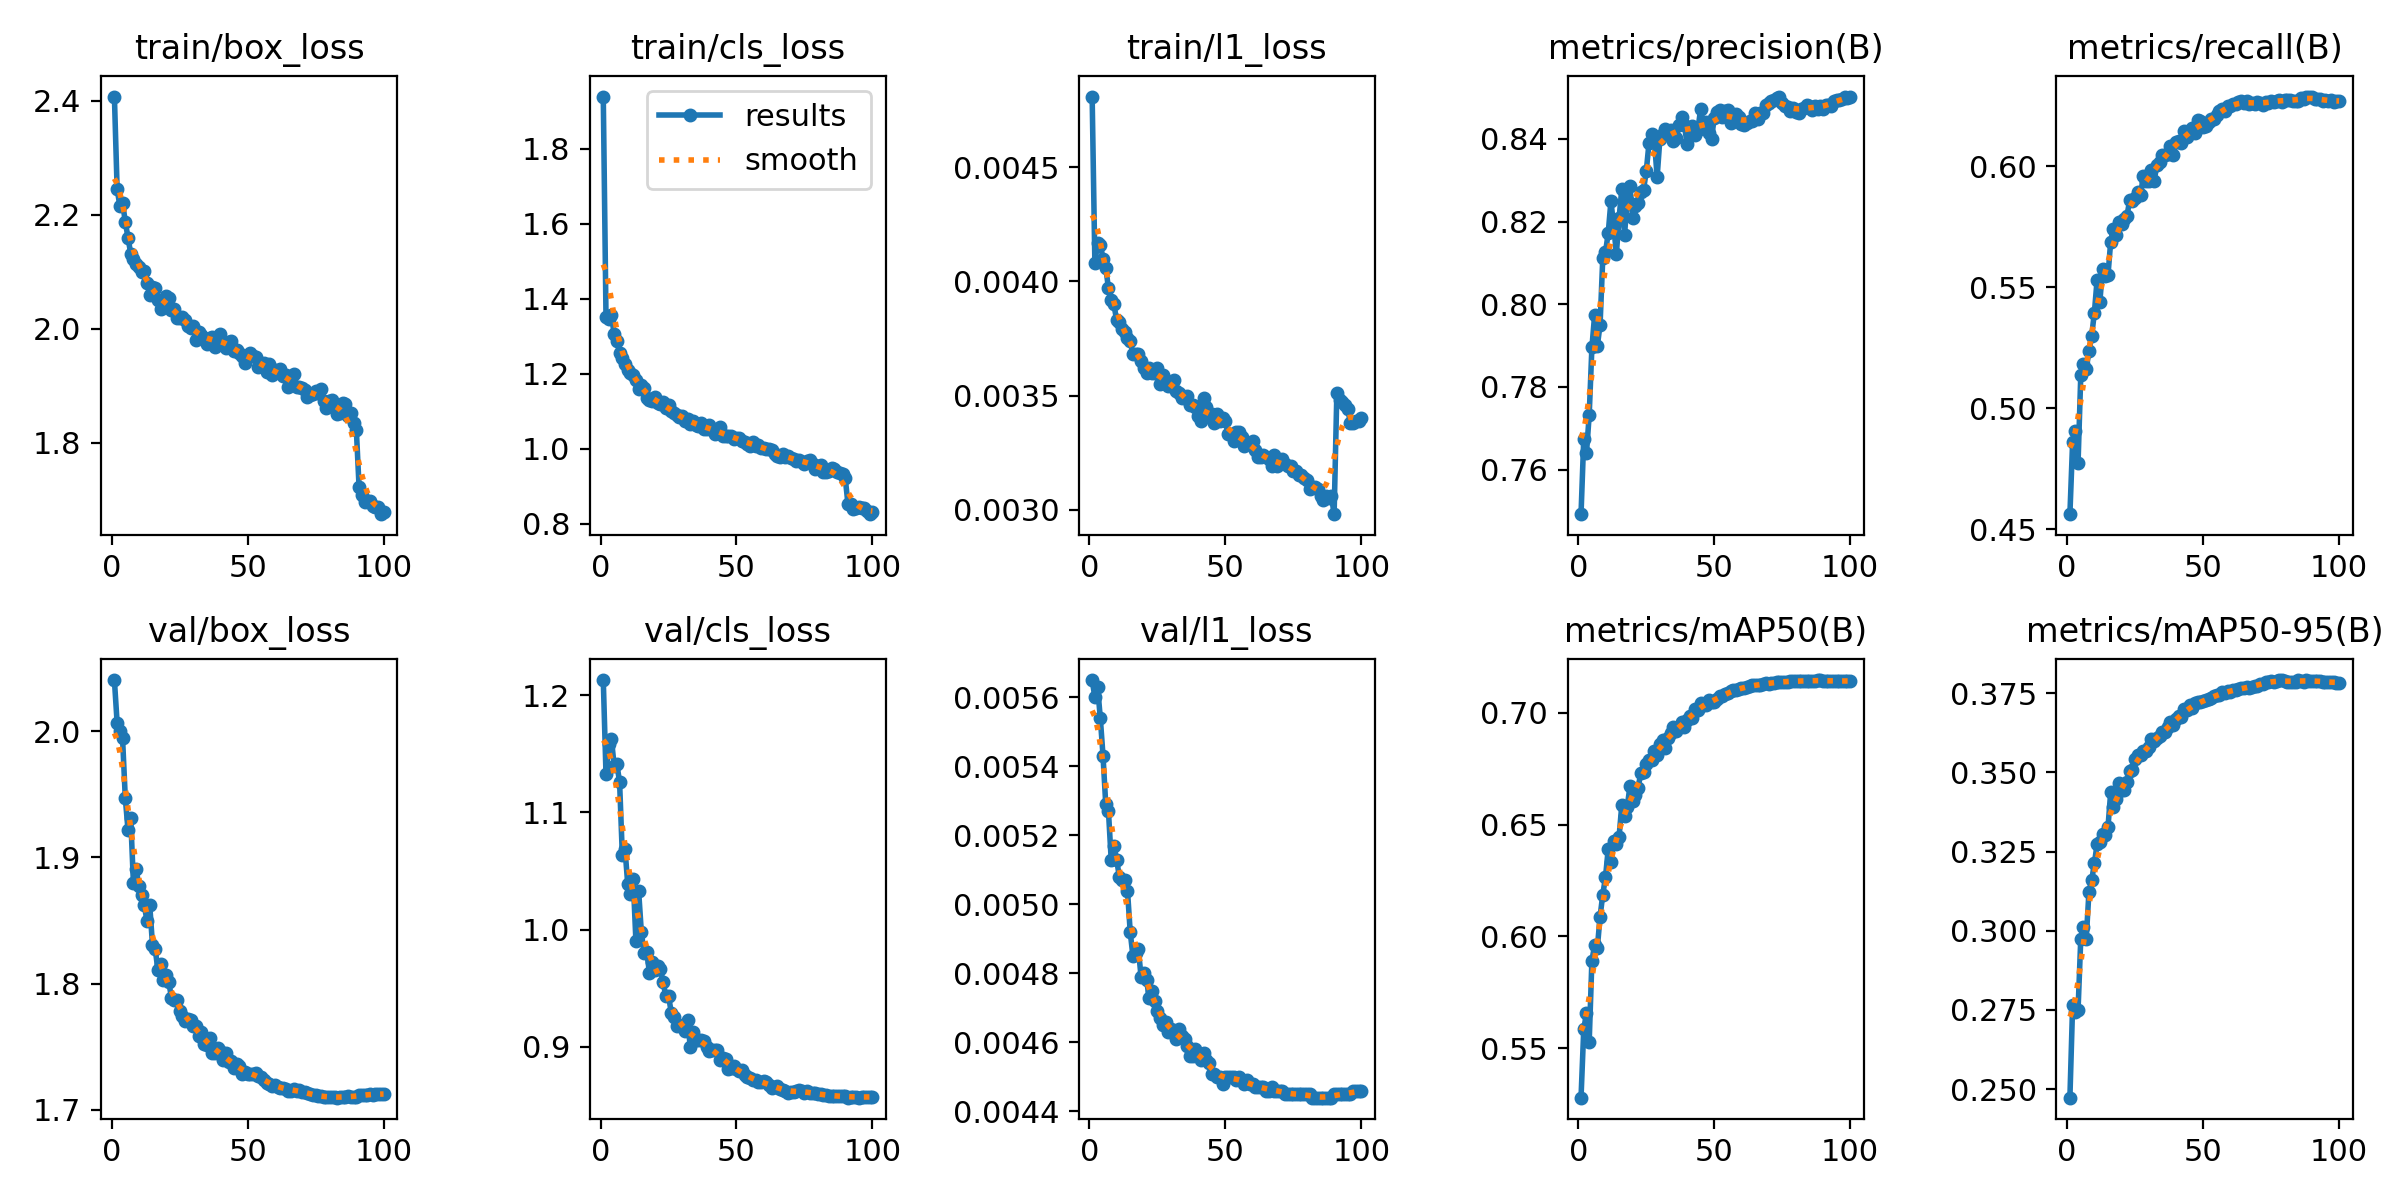

In [ ]:
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError("Ainda não existe best.pt neste experimento.")
training_csv = RUN_DIR / "results.csv"
if training_csv.is_file():
    with training_csv.open(encoding="utf-8-sig") as stream:
        training_rows = list(csv.DictReader(stream))
    completed_epochs = max(int(float(row["epoch"])) for row in training_rows)
    summary = {"epochs_limit": EPOCHS, "completed_epochs": completed_epochs,
               "best_weights": str(BEST_WEIGHTS), "best_weights_sha256": sha256_file(BEST_WEIGHTS)}
    (RUN_DIR / "training_summary.json").write_text(json.dumps(summary, indent=2))
    print("Épocas efetivamente concluídas:", completed_epochs)
print("Melhores pesos:", BEST_WEIGHTS)
if (RUN_DIR / "results.png").is_file():
    display(DisplayImage(filename=str(RUN_DIR / "results.png")))

## Avaliação final dos três modelos: Easy / Medium / Hard

Executa uma passagem de inferência em todas as 3 226 imagens de validação, com o preset `lindevs`.
Os três modelos usam a mesma GPU e configuração nesta sessão. O melhor checkpoint novo substitui apenas
a versão fine-tuned. Os ficheiros MAT oficiais em falta são obtidos com verificação de SHA-256.

O treino e a escolha de `best.pt` usam a validação; estes resultados continuam a ser de validação.
A avaliação não tem épocas de treino adicionais.

Descarregar anotações oficiais: wider_easy_val.mat
Descarregar anotações oficiais: wider_medium_val.mat
Descarregar anotações oficiais: wider_hard_val.mat

Gerar previsões oficiais: YOLO26n base (person) (lindevs)
Previsões: 100/3226 imagens
Previsões: 200/3226 imagens
Previsões: 300/3226 imagens
Previsões: 400/3226 imagens
Previsões: 500/3226 imagens
Previsões: 600/3226 imagens
Previsões: 700/3226 imagens
Previsões: 800/3226 imagens
Previsões: 900/3226 imagens
Previsões: 1000/3226 imagens
Previsões: 1100/3226 imagens
Previsões: 1200/3226 imagens
Previsões: 1300/3226 imagens
Previsões: 1400/3226 imagens
Previsões: 1500/3226 imagens
Previsões: 1600/3226 imagens
Previsões: 1700/3226 imagens
Previsões: 1800/3226 imagens
Previsões: 1900/3226 imagens
Previsões: 2000/3226 imagens
Previsões: 2100/3226 imagens
Previsões: 2200/3226 imagens
Previsões: 2300/3226 imagens
Previsões: 2400/3226 imagens
Previsões: 2500/3226 imagens
Previsões: 2600/3226 imagens
Previsões: 2700/3226 imagens
Previsões: 2

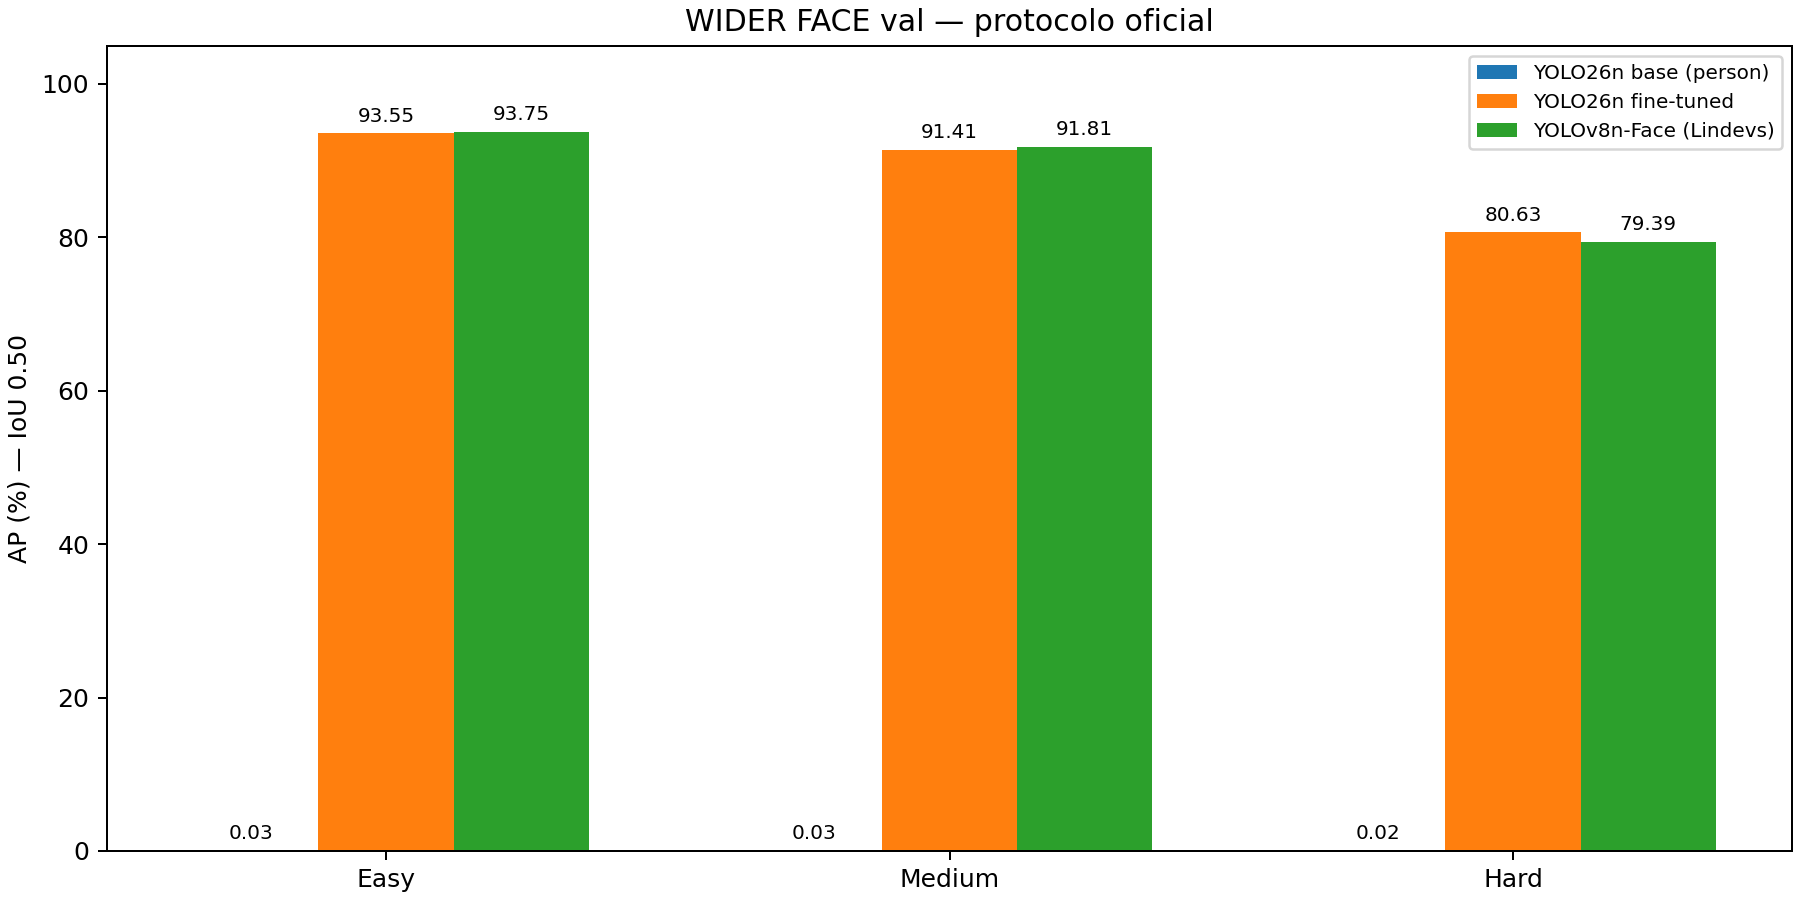

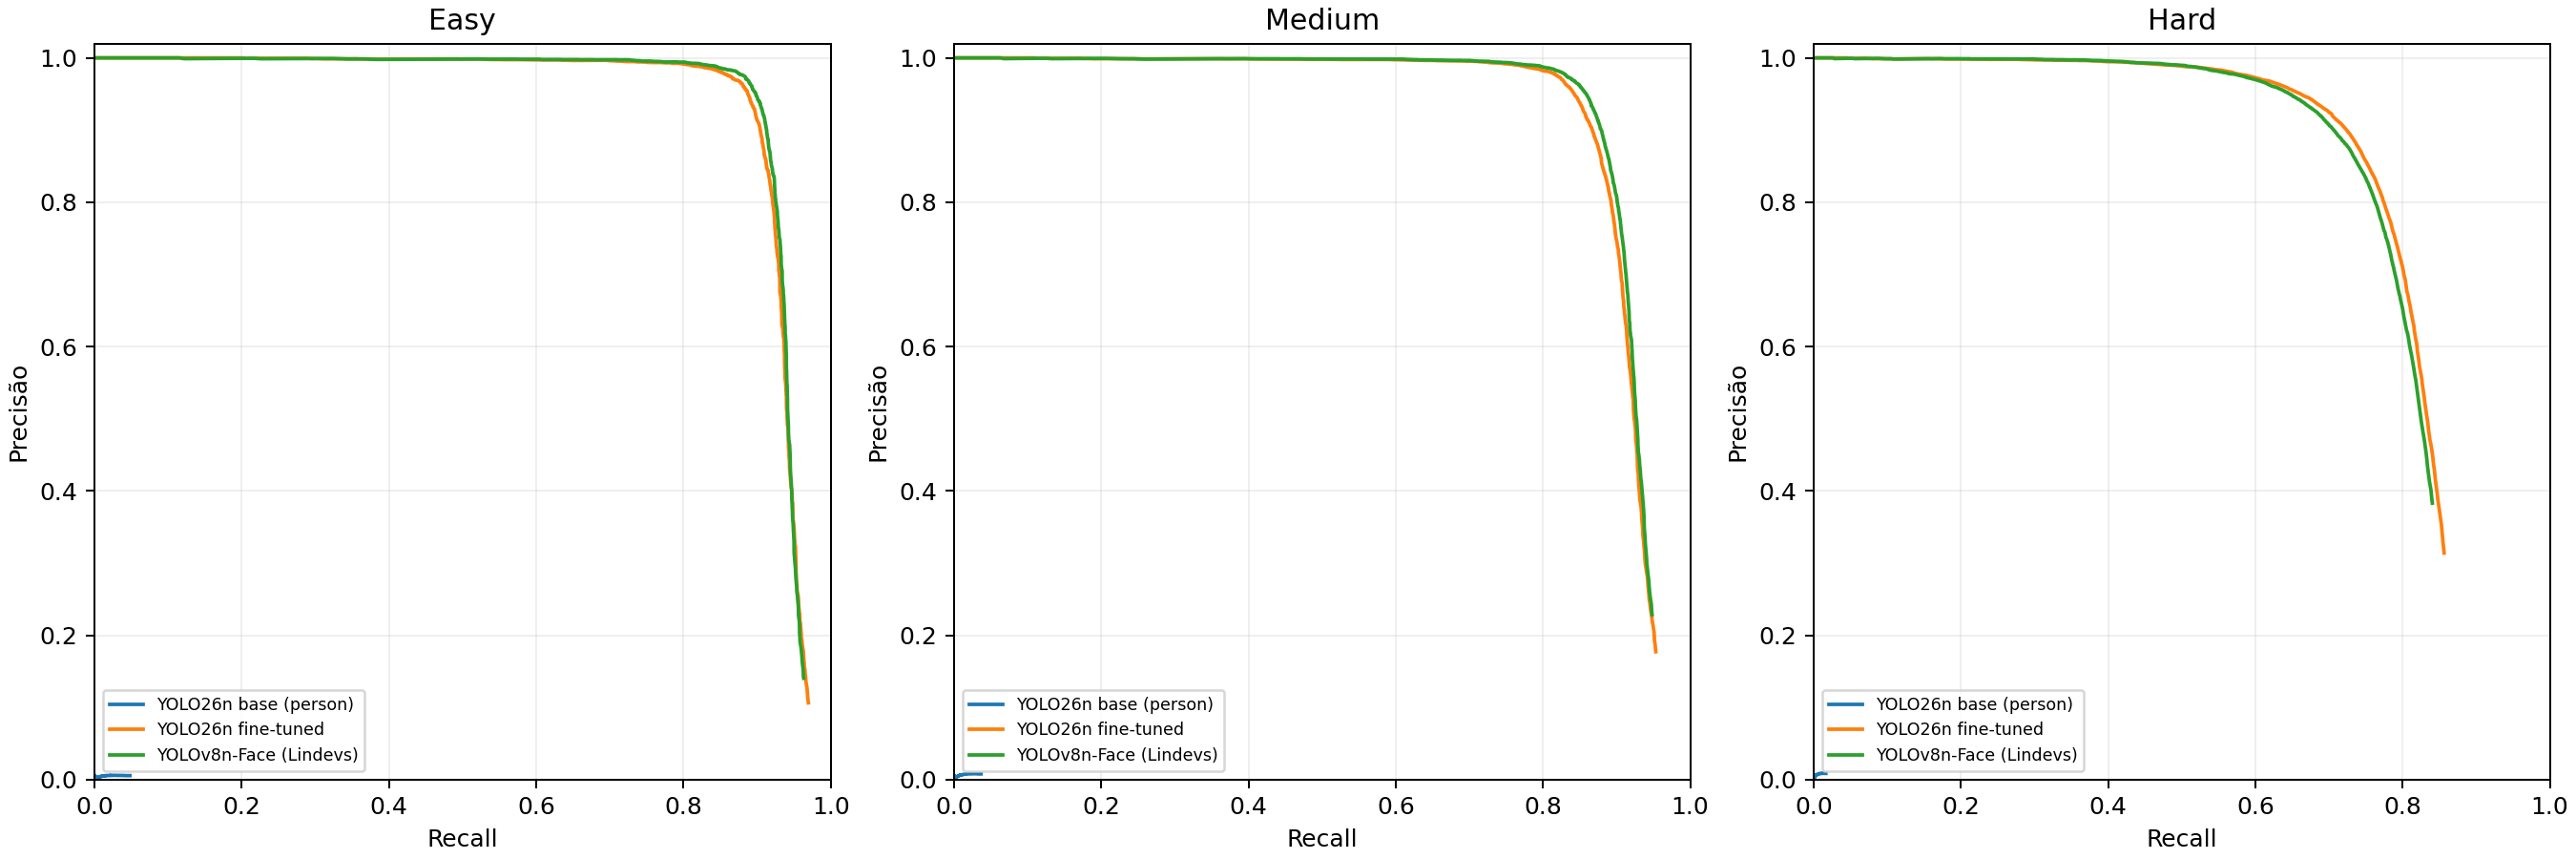

Resultados guardados no Drive: /content/drive/MyDrive/AIA_TP1_colab/evaluations/yolo26n_wider_100ep_v1/20261026T210130570719Z


In [ ]:
if RUN_OFFICIAL_EVALUATION:
    evaluation_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    EVAL_LOCAL = PROJECT_ROOT / "runs/wider_face_comparison" / evaluation_id
    specs = default_model_specs(PROJECT_ROOT, fine_weights=BEST_WEIGHTS)
    official_rows, official_curves = run_wider_comparison(
        specs, DATASET_ROOT / "WIDER_val/images", DATASET_ROOT / "wider_face_split",
        EVAL_LOCAL, device=0, preset="lindevs",
    )
    EVAL_DRIVE = DRIVE_PROJECT / "evaluations" / RUN_NAME / evaluation_id
    EVAL_DRIVE.mkdir(parents=True, exist_ok=False)
    for name in ("comparison.csv", "comparison.json", "manifest.json", "evaluation_images.txt",
                 "curves.npz", "wider_comparison.png", "wider_pr_curves.png"):
        shutil.copy2(EVAL_LOCAL / name, EVAL_DRIVE / name)
    # Uma cópia ZIP conserva também as 9 678 previsões, com menos operações de I/O no Drive.
    archive_path = shutil.make_archive(str(PROJECT_ROOT / f"evaluation_{evaluation_id}"), "zip", root_dir=EVAL_LOCAL)
    shutil.copy2(archive_path, EVAL_DRIVE / "evaluation_with_predictions.zip")
    for row in official_rows:
        print(row["model"], {split: f"{100 * row[split + '_ap']:.2f}%" for split in ("easy", "medium", "hard")})
    display(DisplayImage(filename=str(EVAL_DRIVE / "wider_comparison.png")))
    display(DisplayImage(filename=str(EVAL_DRIVE / "wider_pr_curves.png")))
    print("Resultados guardados no Drive:", EVAL_DRIVE)
else:
    print("Avaliação desativada. Pode voltar noutra sessão com RUN_TRAINING=False.")

## Trazer os pesos e resultados para o computador

No Drive, abrir `AIA_TP1_colab/runs/<RUN_NAME>/weights/` e descarregar **`best.pt`**.
Guardar localmente, por exemplo, como `weights/yolo26n_wider_100ep_best.pt`.
No notebook local `notebooks/yolo.ipynb`, alterar:

```python
FINETUNED_WEIGHTS = PROJECT_ROOT / "weights/yolo26n_wider_100ep_best.pt"
```

Os CSVs e gráficos finais estão em `AIA_TP1_colab/evaluations/<RUN_NAME>/<execução>/`.
Guardar também `results.csv`, `args.yaml`, `experiment.json` e `training_summary.json` para o relatório.
A duração do treino deve ser estimada pelas épocas observadas na GPU atribuída, não pelos tempos de outro equipamento.